In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats

In [66]:
df = pd.read_csv("/content/Jamboree_Admission.csv")
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


**Exploratory Data Analysis**

In [67]:
df.shape

(500, 9)

In [68]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         500 non-null    int64  
 1   GRE Score          500 non-null    int64  
 2   TOEFL Score        500 non-null    int64  
 3   University Rating  500 non-null    int64  
 4   SOP                500 non-null    float64
 5   LOR                500 non-null    float64
 6   CGPA               500 non-null    float64
 7   Research           500 non-null    int64  
 8   Chance of Admit    500 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 35.3 KB


- The datatype of the columns is either integer or float.

In [69]:
df.isnull().sum()/len(df)*100

,0
Serial No.,0.0
GRE Score,0.0
TOEFL Score,0.0
University Rating,0.0
SOP,0.0
LOR,0.0
CGPA,0.0
Research,0.0
Chance of Admit,0.0


- There are no missing values present in the dataset.

In [70]:
df.duplicated().sum()

np.int64(0)

- There are no duplicates present in the dataset.

In [71]:
df.describe()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000,500.00000
mean,250.500000,316.472000,107.192000,3.114000,3.374000,3.48400,8.576440,0.560000,0.72174
std,144.481833,11.295148,6.081868,1.143512,0.991004,0.92545,0.604813,0.496884,0.14114
min,1.000000,290.000000,92.000000,1.000000,1.000000,1.00000,6.800000,0.000000,0.34000
25%,125.750000,308.000000,103.000000,2.000000,2.500000,3.00000,8.127500,0.000000,0.63000
50%,250.500000,317.000000,107.000000,3.000000,3.500000,3.50000,8.560000,1.000000,0.72000
75%,375.250000,325.000000,112.000000,4.000000,4.000000,4.00000,9.040000,1.000000,0.82000
max,500.000000,340.000000,120.000000,5.000000,5.000000,5.00000,9.920000,1.000000,0.97000


In [72]:
df.columns

Index(['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP',
       'LOR ', 'CGPA', 'Research', 'Chance of Admit '],
      dtype='object')

- Column Profiling to understand each column

In [73]:
cat_cols = ['University Rating', 'SOP', 'LOR ', 'Research']
num_cols = ['GRE Score', 'TOEFL Score', 'CGPA']
target = 'Chance of Admit '

In [74]:
df["University Rating"].value_counts(normalize=True)*100

,proportion
University Rating,
3,32.4
2,25.2
4,21.0
5,14.6
1,6.8


In [75]:
df["SOP"].value_counts(normalize=True)*100

,proportion
SOP,
4.0,17.8
3.5,17.6
3.0,16.0
2.5,12.8
4.5,12.6
2.0,8.6
5.0,8.4
1.5,5.0
1.0,1.2


In [76]:
df["LOR "].value_counts(normalize=True)*100

,proportion
LOR,
3.0,19.8
4.0,18.8
3.5,17.2
4.5,12.6
2.5,10.0
5.0,10.0
2.0,9.2
1.5,2.2
1.0,0.2


In [77]:
df["Research"].value_counts(normalize=True)*100

,proportion
Research,
1,56.0
0,44.0


In [78]:
df["Chance of Admit "].value_counts(normalize=True)

,proportion
Chance of Admit,
0.71,0.046
0.64,0.038
0.73,0.036
0.72,0.032
0.79,0.032
...,...
0.60,0.004
0.51,0.004
0.43,0.002


In [79]:
df.drop(columns = ["Serial No."], inplace= True)

- Dropping Serial no. column as we don't want our model to develop any understanding using it's values.

**Univariate Analysis**

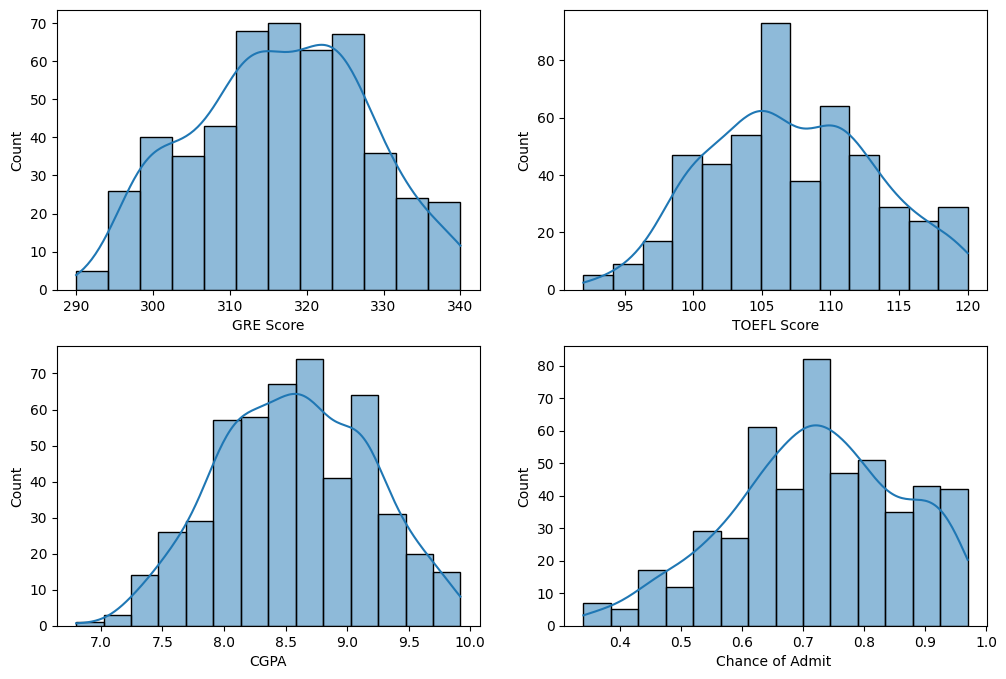

In [80]:
# checking distribution of each numerical variable
rows, cols = 2, 2
fig, axs = plt.subplots(rows,cols, figsize=(12, 8))
index = 0
for row in range(rows):
    for col in range(cols):
        sns.histplot(df[num_cols[index]], kde=True, ax=axs[row,col])
        index += 1
    break

sns.histplot(df[num_cols[-1]], kde=True, ax=axs[1,0])
sns.histplot(df[target], kde=True, ax=axs[1,1])
plt.show()

- GRE Scores are in the range 290 to 340 with most of the students in the scoring in the range 310-320
- TOEFL Scores are in the range 90 to 120 with maximum students scoring in range 105-110
- CGPA is in the range 7-10 with maximum between 8.5 and 9
- Chance of Admit is maximum with 70%-75%

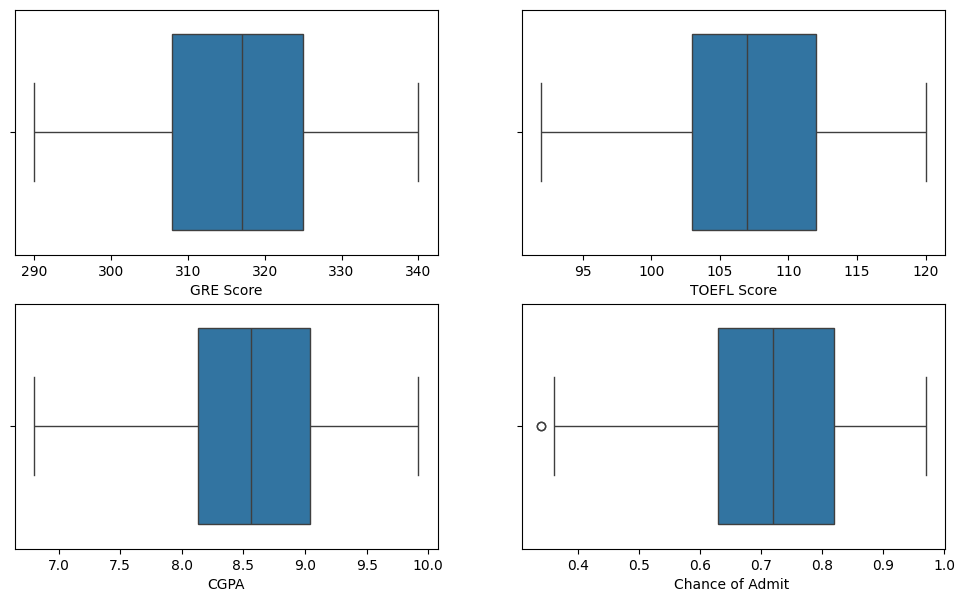

In [81]:
# checking for outliers using boxplots
rows, cols = 2, 2
fig, axs = plt.subplots(rows, cols, figsize=(12, 7))

index = 0
for col in range(cols):
    sns.boxplot(x=num_cols[index], data=df, ax=axs[0,index])
    index += 1

sns.boxplot(x=num_cols[-1], data=df, ax=axs[1,0])
sns.boxplot(x=target, data=df, ax=axs[1,1])
plt.show()

- There are no outliers present in the dataset.

In [82]:
# checking unique values in categorical variables
for col in cat_cols:
    print("Column:  {:18}   Unique values: {}".format(col, df[col].nunique()))

Column:  University Rating    Unique values: 5
Column:  SOP                  Unique values: 9
Column:  LOR                  Unique values: 9
Column:  Research             Unique values: 2


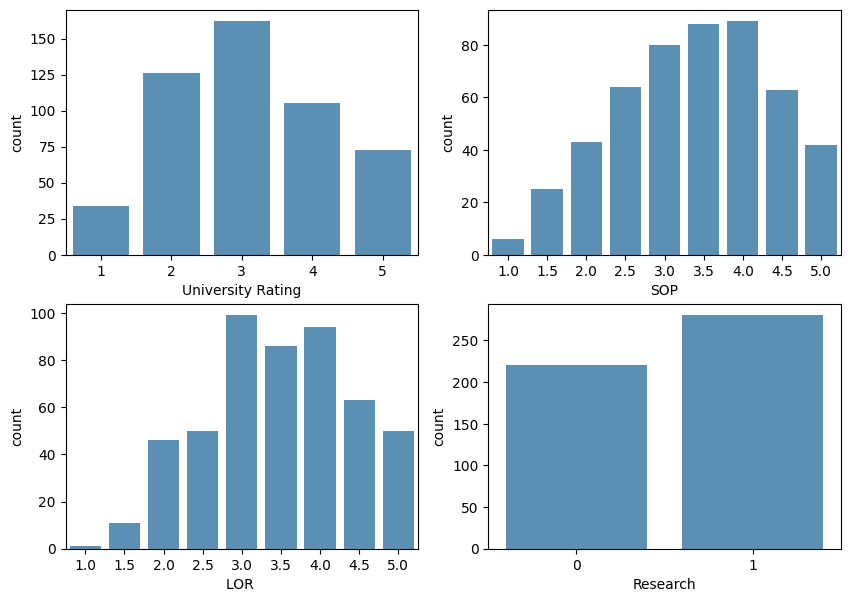

In [83]:
# countplots for categorical variables
cols, rows = 2, 2
fig, axs = plt.subplots(rows, cols, figsize=(10, 7))

index = 0
for row in range(rows):
    for col in range(cols):
        sns.countplot(x=cat_cols[index], data=df, ax=axs[row, col], alpha=0.8)
        index += 1

plt.show()

- Most of the students belong to University with rating 3 followed by 2 and 4
- Maximum students have got Statement of Purpose with strength 4 followed by 3.5 and 3
- Letter of Recommendation with strength 3 have got maximum number of students
- Most of the students have got research done

**Bivariate Analysis**

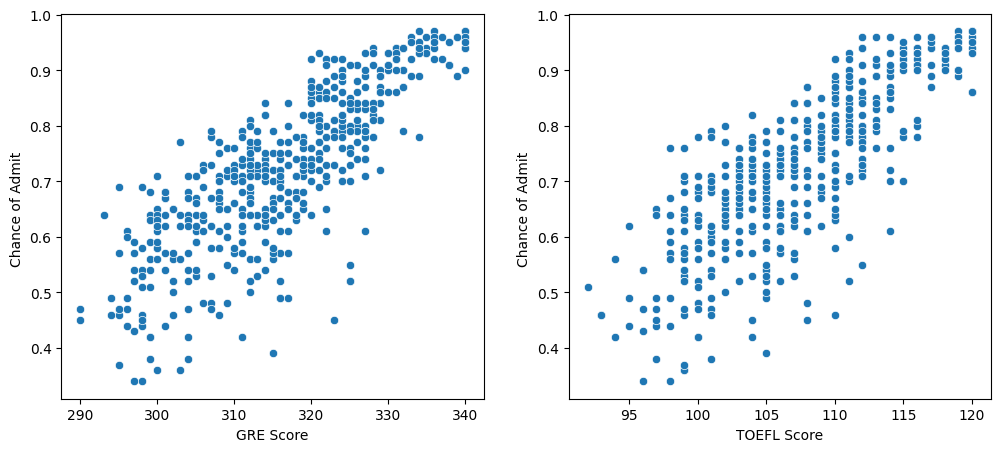

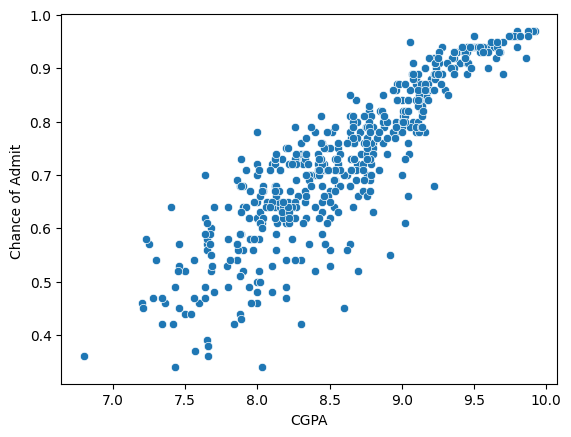

In [84]:
# checking relation between continuous variables & target variable
fig, axs = plt.subplots(1, 2, figsize=(12,5))

sns.scatterplot(x=num_cols[0], y=target, data=df, ax=axs[0])
sns.scatterplot(x=num_cols[1], y=target, data=df, ax=axs[1])
plt.show()
sns.scatterplot(x=num_cols[2], y=target, data=df)
plt.show()

- Seems like there is a linear correlation between the continuous variables and the target variable.

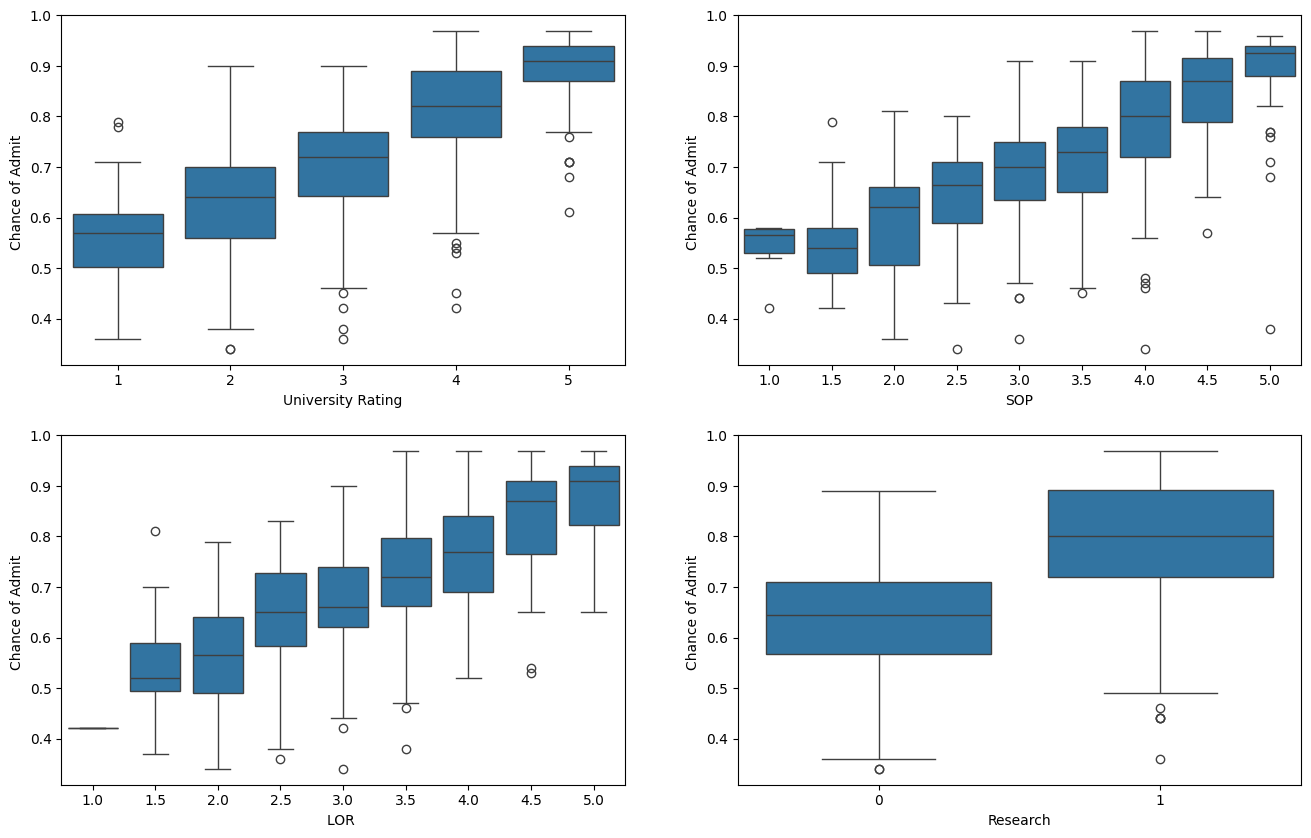

In [85]:
rows, cols = 2,2
fig, axs = plt.subplots(rows, cols, figsize=(16,10))

index = 0
for row in range(rows):
    for col in range(cols):
        sns.boxplot(x=cat_cols[index], y=target, data=df, ax=axs[row,col])
        index += 1

- As you can see from the graphs, as the university rating increases the Chance of Admit also increases.Chance of Admit is highest for University with rating 5 followed by 4,3,2,1.
- Students who have the research experience have more chances of Admission as compared to other students who don't have the research experience.
- COA is maximum for SOP strength of 5 and henceforth decreasing uptil 1.
- LOR with strength 5 has the maximum chance of admit.

**Multivariate Analysis**

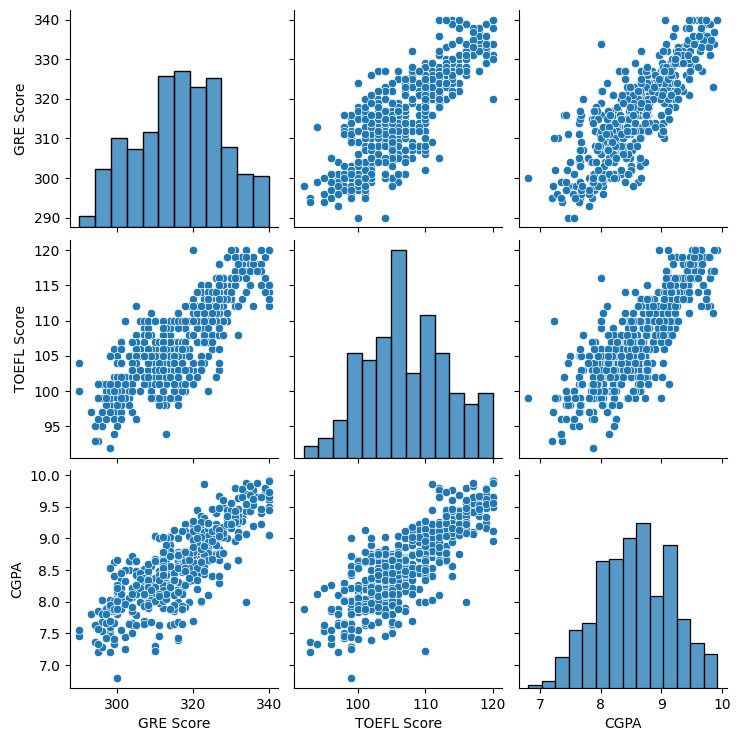

In [86]:
sns.pairplot(df[num_cols])
plt.show()

- Independent continuous variables are also correlated with each other.

In [87]:
df.corr()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
GRE Score,1.000000,0.827200,0.635376,0.613498,0.524679,0.825878,0.563398,0.810351
TOEFL Score,0.827200,1.000000,0.649799,0.644410,0.541563,0.810574,0.467012,0.792228
University Rating,0.635376,0.649799,1.000000,0.728024,0.608651,0.705254,0.427047,0.690132
SOP,0.613498,0.644410,0.728024,1.000000,0.663707,0.712154,0.408116,0.684137
LOR,0.524679,0.541563,0.608651,0.663707,1.000000,0.637469,0.372526,0.645365
CGPA,0.825878,0.810574,0.705254,0.712154,0.637469,1.000000,0.501311,0.882413
Research,0.563398,0.467012,0.427047,0.408116,0.372526,0.501311,1.000000,0.545871
Chance of Admit,0.810351,0.792228,0.690132,0.684137,0.645365,0.882413,0.545871,1.000000


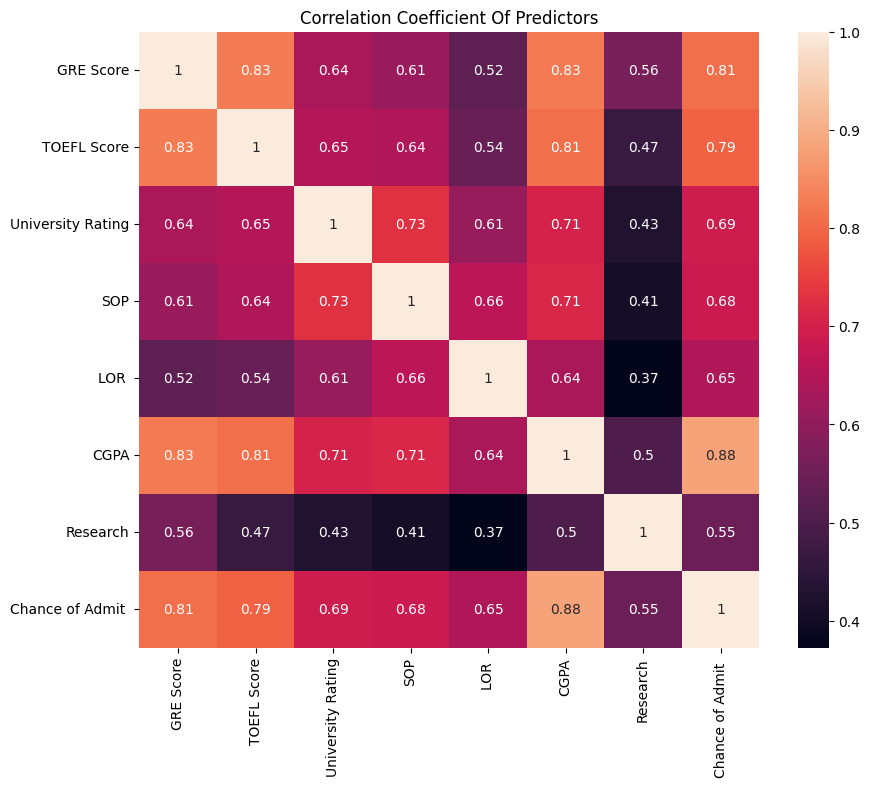

In [88]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True)
plt.title('Correlation Coefficient Of Predictors')
plt.show()

**Looking at the correlation above between various columns with our target column (Chance of Admit), I can say the following -**

- There is a high correlation between GRE Score, TOEFL Score and Chance of Admit.
- There is a some correlation between University Rating, SOP, LOR and Chance of Admit.
- There is a very high correlation between CGPA and Chance of Admit.
- Research column has least effect in comparision to all others on Chances of Admission.

**By looking at the insights above we can say that the given problem is a LINEAR REGRESSION problem.**

**Data Preprocessing for model building**

In [89]:
df.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,337,118,4,4.5,4.5,9.65,1,0.92
1,324,107,4,4.0,4.5,8.87,1,0.76
2,316,104,3,3.0,3.5,8.00,1,0.72
3,322,110,3,3.5,2.5,8.67,1,0.80
4,314,103,2,2.0,3.0,8.21,0,0.65


In [90]:
# separate predictor and target variables
X = df.drop(columns=[target])
y = df[target]

In [91]:
# standardize the dataset
sc = StandardScaler()
X = sc.fit_transform(X)

In [92]:
# performing Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

In [93]:
# splitting the data into training and test data

print(f'Shape of x_train: {X_train.shape}')
print(f'Shape of x_test: {X_test.shape}')
print(f'Shape of y_train: {y_train.shape}')
print(f'Shape of y_test: {y_test.shape}')

Shape of x_train: (350, 7)
Shape of x_test: (150, 7)
Shape of y_train: (350,)
Shape of y_test: (150,)


**Model Building**

In [94]:
X_sm = sm.add_constant(X_train)
sm_model = sm.OLS(y_train, X_sm).fit()

print(sm_model.summary())

                            OLS Regression Results                            
Dep. Variable:       Chance of Admit    R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.817
Method:                 Least Squares   F-statistic:                     224.1
Date:                Sat, 16 Aug 2025   Prob (F-statistic):          1.27e-123
Time:                        15:17:07   Log-Likelihood:                 500.20
No. Observations:                 350   AIC:                            -984.4
Df Residuals:                     342   BIC:                            -953.5
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.7250      0.003    230.864      0.0

In [95]:
def adjusted_r2(r2, p, n):
    """
    n: no of samples
    p: no of predictors
    r2: r2 score
    """
    adj_r2 = 1 - ((1-r2)*(n-1) / (n-p-1))
    return adj_r2

def get_metrics(y_true, y_pred, p=None):
    n = y_true.shape[0]
    mse = np.sum((y_true - y_pred)**2) / n
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    score = r2_score(y_true, y_pred)
    adj_r2 = None
    if p is not None:
        adj_r2 = adjusted_r2(score, p, n)

    res = {
        "mean_absolute_error": round(mae, 2),
        "rmse": round(rmse, 2),
        "r2_score": round(score, 2),
        "adj_r2": round(adj_r2, 2)
    }
    return res

In [96]:
def train_model(X_train, y_train, X_test, y_test,cols, model_name="linear", alpha=1.0):
    model = None
    if model_name == "lasso":
        model = Lasso(alpha=alpha)
    elif model_name == "ridge":
        model = Ridge(alpha=alpha)
    else:
        model = LinearRegression()

    model.fit(X_train, y_train)
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    p = X_train.shape[1]
    train_res = get_metrics(y_train, y_pred_train, p)
    test_res = get_metrics(y_test, y_pred_test, p)

    print(f"\n----   {model_name.title()} Regression Model  ----\n")
    print(f"Train MAE: {train_res['mean_absolute_error']} Test MAE: {test_res['mean_absolute_error']}")
    print(f"Train RMSE: {train_res['rmse']} Test RMSE: {test_res['rmse']}")
    print(f"Train R2_score: {train_res['r2_score']} Test R2_score: {test_res['r2_score']}")
    print(f"Train Adjusted_R2: {train_res['adj_r2']} Test Adjusted_R2: {test_res['adj_r2']}")
    print(f"Intercept: {model.intercept_}")
    #print(len(df.columns), len(model.coef_))
    coef_df = pd.DataFrame({"Column": cols, "Coef": model.coef_})
    print(coef_df)
    print("-"*50)
    return model

In [97]:
train_model(X_train, y_train, X_test, y_test,df.columns[:-1], "linear")
train_model(X_train, y_train, X_test, y_test,df.columns[:-1], "ridge")
train_model(X_train, y_train, X_test, y_test,df.columns[:-1], "lasso", 0.001)


----   Linear Regression Model  ----

Train MAE: 0.04 Test MAE: 0.04
Train RMSE: 0.06 Test RMSE: 0.06
Train R2_score: 0.82 Test R2_score: 0.82
Train Adjusted_R2: 0.82 Test Adjusted_R2: 0.81
Intercept: 0.724978121476996
              Column      Coef
0          GRE Score  0.018657
1        TOEFL Score  0.023176
2  University Rating  0.011565
3                SOP -0.000999
4               LOR   0.012497
5               CGPA  0.064671
6           Research  0.013968
--------------------------------------------------

----   Ridge Regression Model  ----

Train MAE: 0.04 Test MAE: 0.04
Train RMSE: 0.06 Test RMSE: 0.06
Train R2_score: 0.82 Test R2_score: 0.82
Train Adjusted_R2: 0.82 Test Adjusted_R2: 0.81
Intercept: 0.7249823645841696
              Column      Coef
0          GRE Score  0.018902
1        TOEFL Score  0.023252
2  University Rating  0.011594
3                SOP -0.000798
4               LOR   0.012539
5               CGPA  0.064004
6           Research  0.013990
-------------

Lasso(alpha=0.001)

**Evaluating Model Performance**

- The model performs well on both the training and testing sets, as indicated by small MAE and RMSE values and high R-squared and adjusted R-squared values.

- The model appears to generalize well to unseen data (testing set), as the performance metrics on the testing set are comparable to those on the training set.

**Linear Regression Model - Assumption Test**

Mutlicollinearity Check

In [98]:
def vif(newdf):
    # VIF dataframe
    vif_data = pd.DataFrame()
    vif_data["feature"] = newdf.columns

    # calculating VIF for each feature
    vif_data["VIF"] = [variance_inflation_factor(newdf.values, i)
                              for i in range(len(newdf.columns))]
    return vif_data

In [99]:
res = vif(df.iloc[:,:-1])
res

,feature,VIF
0,GRE Score,1308.061089
1,TOEFL Score,1215.951898
2,University Rating,20.933361
3,SOP,35.265006
4,LOR,30.911476
5,CGPA,950.817985
6,Research,2.869493


In [100]:
# dropping GRE Score and again calculating the VIF
res = vif(df.iloc[:, 1:-1])
res

,feature,VIF
0,TOEFL Score,639.741892
1,University Rating,19.884298
2,SOP,33.733613
3,LOR,30.631503
4,CGPA,728.778312
5,Research,2.863301


In [101]:
# # dropping TOEFL Score and again calculating the VIF
res = vif(df.iloc[:,2:-1])
res

,feature,VIF
0,University Rating,19.777410
1,SOP,33.625178
2,LOR,30.356252
3,CGPA,25.101796
4,Research,2.842227


In [102]:
# Now lets drop the SOP and again calculate VIF
res = vif(df.iloc[:,2:-1].drop(columns=['SOP']))
res

,feature,VIF
0,University Rating,15.140770
1,LOR,26.918495
2,CGPA,22.369655
3,Research,2.819171


In [103]:
# lets drop the LOR as well
newdf = df.iloc[:,2:-1].drop(columns=['SOP'])
newdf = newdf.drop(columns=['LOR '], axis=1)
res = vif(newdf)
res

,feature,VIF
0,University Rating,12.498400
1,CGPA,11.040746
2,Research,2.783179


In [104]:
# Now dropping the University Rating as well
newdf = newdf.drop(columns=['University Rating'])
res = vif(newdf)
res

,feature,VIF
0,CGPA,2.455008
1,Research,2.455008


- VIF Value is now well below 5 which means this model is good to go ahead

In [105]:
# training the model with only these two features
X = df[['CGPA', 'Research']]
sc = StandardScaler()
X = sc.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

In [106]:
model = train_model(X_train, y_train, X_test, y_test, ['CGPA', 'Research'], "linear")
train_model(X_train, y_train, X_test, y_test, ['CGPA', 'Research'], "ridge")
train_model(X_train, y_train, X_test, y_test, ['CGPA', 'Research'], "lasso", 0.001)


----   Linear Regression Model  ----

Train MAE: 0.05 Test MAE: 0.05
Train RMSE: 0.06 Test RMSE: 0.07
Train R2_score: 0.78 Test R2_score: 0.81
Train Adjusted_R2: 0.78 Test Adjusted_R2: 0.81
Intercept: 0.7247774222727991
     Column      Coef
0      CGPA  0.112050
1  Research  0.020205
--------------------------------------------------

----   Ridge Regression Model  ----

Train MAE: 0.05 Test MAE: 0.05
Train RMSE: 0.06 Test RMSE: 0.07
Train R2_score: 0.78 Test R2_score: 0.81
Train Adjusted_R2: 0.78 Test Adjusted_R2: 0.81
Intercept: 0.7247830300095277
     Column      Coef
0      CGPA  0.111630
1  Research  0.020362
--------------------------------------------------

----   Lasso Regression Model  ----

Train MAE: 0.05 Test MAE: 0.05
Train RMSE: 0.06 Test RMSE: 0.07
Train R2_score: 0.78 Test R2_score: 0.81
Train Adjusted_R2: 0.78 Test Adjusted_R2: 0.81
Intercept: 0.7247713356661623
     Column      Coef
0      CGPA  0.111344
1  Research  0.019571
---------------------------------------

Lasso(alpha=0.001)

- After removing collinear features using VIF and using only two features. R2_score and Adjusted_r2 are still the same as before the testing dataset.

Mean of Residuals

- The RMSE is found to be close to 0 indicating a tendency for underestimation, the small magnitude indicates that the model's predictions are generally close to the actual values.

Linearity of variables

- It is quite clear from EDA that CGPA / GRE Score / TOEFL Score almost show linear relationship with the target variable which can be observed with correlation matrix / pairplot and the p_value of the test statistic in the OLS Regression Summary.

Normality of Residuals

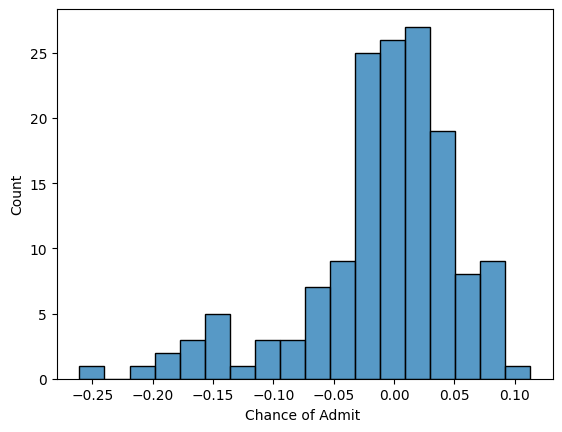

In [107]:
y_pred = model.predict(X_test)
residuals = (y_test - y_pred)
sns.histplot(residuals)
plt.show()

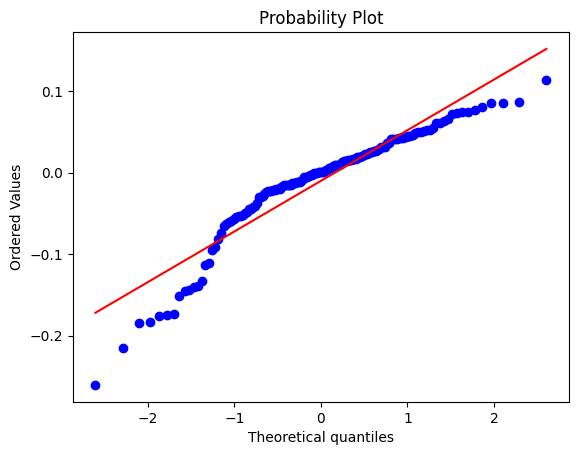

In [108]:
stats.probplot(residuals, plot=plt)
plt.show()

In [109]:
res = stats.shapiro(residuals)
res.statistic

np.float64(0.8991154889966296)

- Closer the value to 1, more is the normality.

- In this case, a value of 0.89 denotes a high level of normality for the error distribuiton

- Graphical Representation and Statistical proof namely Shapiro Wilk Test, both prove that the Residual errors are following normal distribution.

Test for Homoscedasticity

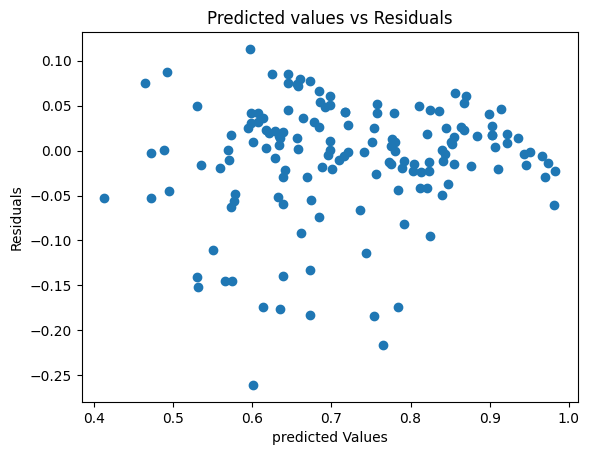

In [110]:
plt.scatter(y_pred, residuals)
plt.xlabel("predicted Values")
plt.ylabel("Residuals")
plt.title("Predicted values vs Residuals")
plt.show()

- Since the plot is not creating a cone type shape. Hence there is no homoscedasticity present in the data.

In [111]:
# Using Goldfeld Quandt Test to check homoskedacity

from statsmodels.compat import lzip
import statsmodels.stats.api as sms

name = ['F statistic', 'p-value']
test = sms.het_goldfeldquandt(y_train, X_sm)
lzip(name, test)

[('F statistic', np.float64(1.1435083878793828)),
 ('p-value', np.float64(0.19355661267569785))]

- F Statistic comes out to be 1.143 => Implying minimal difference in variance between groups.

- p-value of 0.193 indicates that this difference is statistically significant at conventional levels of significance (e.g., 0.05).

- Therefore, we accept the null hypothesis of homoscedasticity, and conclude that there is no strong evidence of heteroscedasticity in the data.

**Identyfying Better Model**

- Following are the final model results on the test data:
 - RMSE: 0.07
 - MAE: 0.05
 - R2_score: 0.81
 - Adjusted_R2: 0.81

- We can observe that both Linear Regression and Ridge Regression have similar accuracy while Lasso regression has oversimplified the model.


**Insights**

- Multicollinearity is present in the data.

- After removing collinear features there are only two variables which are important in making predictions for the target variables.

- Indepedent variables are linearly correlated with dependent variables.

- Chance of Admit show strong positive correlation to CGPA, GRE Score, TOEFL Score.

- Research shows weak positive correlation to all other factors.

- Most of the students belong to University with rating 3 followed by 2 and 4.

- Maximum students have got Statement of Purpose with strength 4 followed by 3.5 and 3.

- Letter of Recommendation with strength 3 have got maximum number of students Most of the students have got research done.

- Chance of Admit is highest for University with rating 5 followed by 4,3,2,1.

- Chance of Admit is maximum for SOP strength of 5 and henceforth decreasing uptil 1.

- LOR with strength 5 has the maximum chance of admit.

- Students who have done research have higher chance of admit.

- It is clear from above that 'University Rating' and 'SOP' have p-value>0.05 , signifying that these two features have no statistically significant effect on the dependent variable. Therefore, these two features were removed from modeling.

- Low Prob(F-statistic) value indicate that the model is statistically significant.

- CGPA carry maximum weightage followed by GRE Score, TOEFL Score, LOR and Research signifying strength of relationship with the dependent variable.

- Linear Regression model performs well on both the training and testing sets, as indicated by small MAE and RMSE values and high R-squared and adjusted R-squared values.

**Recommendations**

**Feature Selection and Model Improvement:**

- CGPA and Research are the only two variables which are important in making the prediction for Chance of Admit.
- CGPA is the most important varibale in making the prediction for the Chance of Admit.
- It's evident that certain features such as 'University Rating' and 'SOP' have been found to have no statistically significant effect on the dependent variable ('Chance of Admit'). Consider revisiting the feature selection process and exploring alternative features that may have a stronger impact on graduate admissions.

**Additional Data Sources:**

- Explore the possibility of incorporating additional data sources to enhance the predictive power of the model. This could include demographic data, extracurricular activities, work experience, or information about specific academic programs.
- Collaborate with educational institutions or other organizations to gather comprehensive datasets that capture various aspects of student profiles and their chances of admission to IVY league colleges.

**Model Implementation and Real-world Application:**

- Once the model is refined and validated, integrate it into Jamboree's website as a user-friendly tool for students to assess their chances of admission to IVY league colleges.
- Provide clear explanations and interpretations of the model's predictions to help students understand the factors influencing their chances of admission.
- Continuously monitor and update the model based on feedback and changes in admission criteria or trends in graduate admissions.

**Business Benefits:**

- Improving the accuracy and reliability of the admission prediction model can enhance Jamboree's reputation and credibility among students and parents.
- A more accurate prediction model can attract more users to Jamboree's website, increasing traffic and engagement with their services.
- By offering valuable insights into graduate admissions, Jamboree can position itself as a trusted advisor and partner in students' academic journeys, potentially leading to increased enrollments in their test preparation programs.

**Continuous Evaluation and Optimization:**

- Regularly evaluate the model's performance against new data and emerging trends in graduate admissions.
Conduct A/B testing and experiments to assess the impact of model enhancements and updates on user engagement and satisfaction.
- Stay informed about advancements in machine learning and predictive modeling techniques to leverage the latest methodologies for improving the admission prediction model.

**By implementing these recommendations, Jamboree can not only enhance the accuracy and reliability of its admission prediction model but also provide valuable support and guidance to students aspiring to gain admission to IVY league colleges.**